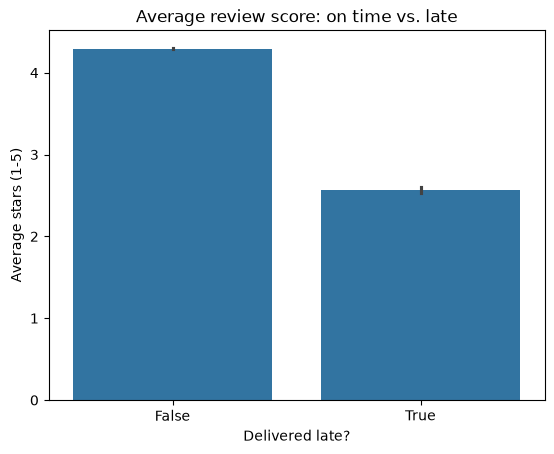

In [1]:
# Load libraries
import sqlite3                     # connects Python to the database
import pandas as pd                # tables (like data.frame in R)
import seaborn as sns              # charts (like ggplot2)
import matplotlib.pyplot as plt    # titles and labels for charts

con = sqlite3.connect("../olist.db")  # open your database

# Same idea as query 2, but one row per order: days late and star rating
df = pd.read_sql("""
SELECT r.review_score,
       julianday(o.order_delivered_customer_date)
       - julianday(o.order_estimated_delivery_date) AS days_late   -- negative = early
FROM olist_orders_dataset o
JOIN olist_order_reviews_dataset r ON o.order_id = r.order_id
WHERE o.order_delivered_customer_date <> ''
""", con)

df["late"] = df["days_late"] > 0          # True if delivered after the promised date

# Chart: average stars for late vs on time
sns.barplot(data=df, x="late", y="review_score")
plt.title("Average review score: on time vs. late")
plt.xlabel("Delivered late?")
plt.ylabel("Average stars (1-5)")
plt.show()

In [2]:
from scipy import stats            # statistics library (like t.test() in R)

on_time = df[df["late"] == False]["review_score"]   # stars of on-time orders
late    = df[df["late"] == True]["review_score"]    # stars of late orders

# Welch t-test: are the two averages really different, or just by chance?
t, p = stats.ttest_ind(on_time, late, equal_var=False)
print(f"Mean on time: {on_time.mean():.2f}, mean late: {late.mean():.2f}")
print(f"t = {t:.1f}, p-value = {p:.3g}")

# Share of bad reviews (1-2 stars) in each group: easier for business people
print("Share of 1-2 star reviews:")
print(df.groupby("late")["review_score"].apply(lambda s: round(100 * (s <= 2).mean(), 1)))

Mean on time: 4.29, mean late: 2.57
t = 89.6, p-value = 0
Share of 1-2 star reviews:
late
False     9.2
True     54.0
Name: review_score, dtype: float64


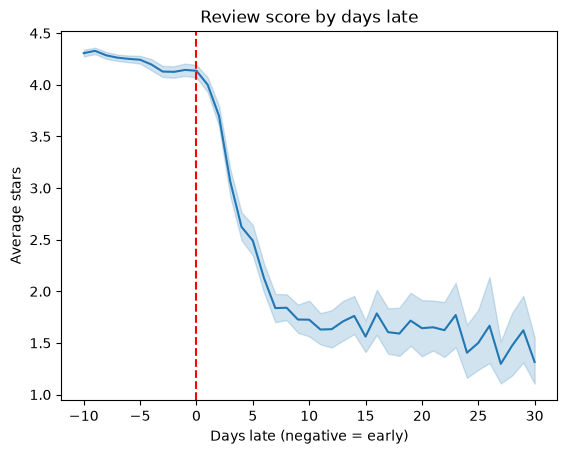

In [3]:
# Round days late to whole days and keep -10 to +30 days
df["days"] = df["days_late"].round()
d = df[(df["days"] >= -10) & (df["days"] <= 30)]

sns.lineplot(data=d, x="days", y="review_score")
plt.axvline(0, color="red", linestyle="--")      # red line = promised delivery date
plt.title("Review score by days late")
plt.xlabel("Days late (negative = early)")
plt.ylabel("Average stars")
plt.show()

## Key findings
1. About 8% of delivered orders arrived late (7,827 orders).
2. Late orders get an average of 2.57 stars vs. 4.29 for on-time orders (Welch t-test, p < 0.001).
3. 54% of late orders receive a 1–2 star review, compared to 9.2% of on-time orders.
4. Northeastern states are hit hardest: AL 23.9% late, MA 19.7%.
5. Ratings collapse within the first week of delay (from 4.1 to about 1.8 stars), while early delivery adds little. Promising realistic delivery dates matters more than delivering fast.

**Recommendation:** Improving delivery reliability in the Northeast would reduce bad reviews the most.

In [4]:
# One row per delivered order with everything the dashboard needs
dash = pd.read_sql("""
SELECT o.order_id,
       substr(o.order_purchase_timestamp, 1, 7) AS month,       -- e.g. 2017-05
       c.customer_state AS state,
       r.review_score,
       julianday(o.order_delivered_customer_date)
       - julianday(o.order_estimated_delivery_date) AS days_late,
       CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date
            THEN 'Late' ELSE 'On time' END AS delivery
FROM olist_orders_dataset o
JOIN olist_customers_dataset c ON o.customer_id = c.customer_id
JOIN olist_order_reviews_dataset r ON o.order_id = r.order_id
WHERE o.order_delivered_customer_date <> ''
""", con)
dash.to_csv("../data/dashboard_data.csv", index=False)   # save into the data folder
print(len(dash), "rows saved")

96359 rows saved
